In [33]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

titanic_data = pd.read_csv("train.csv")
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [34]:
titanic_data['Survived'][titanic_data['Survived'] == 1].count()

np.int64(342)

In [35]:
titanic_data.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [36]:
titanic_data.shape

(891, 12)

In [37]:
titanic_data.drop('Cabin', axis=1, inplace=True)

In [38]:
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].mean())

In [39]:
titanic_data.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


<Axes: >

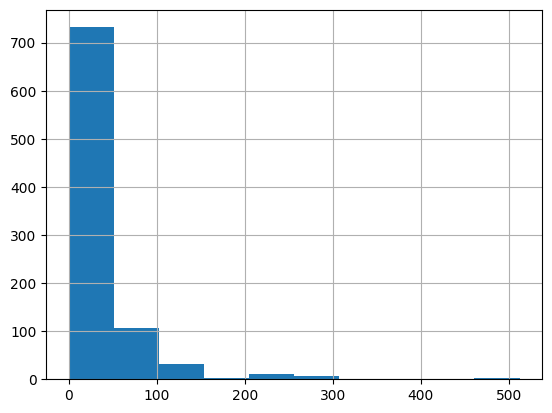

In [40]:
titanic_data['Fare'].hist()

In [41]:
Q1 = titanic_data['Fare'].quantile(0.25)
Q3 = titanic_data['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

titanic_data['Fare'] = titanic_data['Fare'].clip(lower, upper) # assignes values beyond the boundaries - boundary values

In [42]:
sc = StandardScaler() # normalizes our data

titanic_data['Fare_sc'] = sc.fit_transform(titanic_data[['Fare']])
titanic_data['Age_sc'] = sc.fit_transform(titanic_data[['Age']])

titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Fare_sc,Age_sc
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,-0.820552,-0.592481
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,65.6344,C,2.031623,0.638789
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,-0.787578,-0.284663
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1.419297,0.407926
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,-0.781471,0.407926


<Axes: >

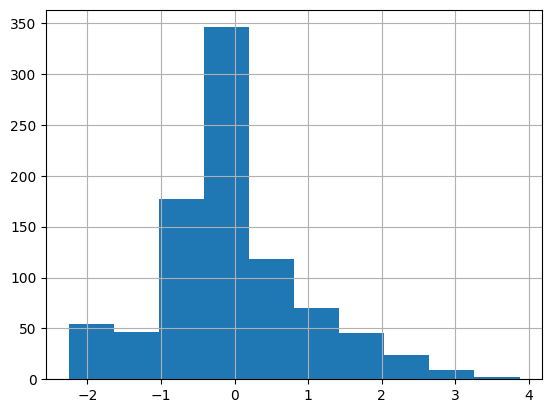

In [43]:
titanic_data['Age_sc'].hist()

<Axes: >

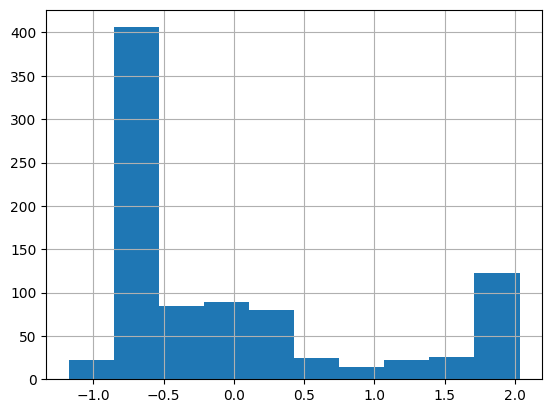

In [44]:
titanic_data['Fare_sc'].hist()

In [45]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Fare_sc,Age_sc
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,-0.820552,-0.592481
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,65.6344,C,2.031623,0.638789
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,-0.787578,-0.284663
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1.419297,0.407926
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,-0.781471,0.407926


In [46]:
titanic_data['Title'] = titanic_data['Name'].apply(lambda x: x.split(',')[1].split('.')[0])

In [51]:
unique_titles = list(titanic_data.Title.unique())
unique_titles

[' Mr',
 ' Mrs',
 ' Miss',
 ' Master',
 ' Don',
 ' Rev',
 ' Dr',
 ' Mme',
 ' Ms',
 ' Major',
 ' Lady',
 ' Sir',
 ' Mlle',
 ' Col',
 ' Capt',
 ' the Countess',
 ' Jonkheer']

Label encoder is good when we have binary categories, One-hot is better for more classes


In [54]:
le = LabelEncoder()

titanic_data['Sex'] = le.fit_transform(titanic_data['Sex'])
titanic_data['Embarked'] = le.fit_transform(titanic_data['Embarked'])
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Fare_sc,Age_sc,Title
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,2,-0.820552,-0.592481,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,65.6344,0,2.031623,0.638789,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,2,-0.787578,-0.284663,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,1.419297,0.407926,Mrs
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,2,-0.781471,0.407926,Mr


In [56]:
titanic_data = pd.concat([titanic_data, pd.get_dummies(titanic_data['Title'])], axis=1)
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir,the Countess
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,...,False,False,False,False,True,False,False,False,False,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,65.6344,...,False,False,False,False,False,True,False,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,...,False,True,False,False,False,False,False,False,False,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,...,False,False,False,False,False,True,False,False,False,False
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,...,False,False,False,False,True,False,False,False,False,False


In [58]:
titanic_data = titanic_data.drop(['PassengerId','Name', 'Ticket', 'Title'], axis=1)
titanic_data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Fare_sc,Age_sc,...,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir,the Countess
0,0,3,1,22.0,1,0,7.2500,2,-0.820552,-0.592481,...,False,False,False,False,True,False,False,False,False,False
1,1,1,0,38.0,1,0,65.6344,0,2.031623,0.638789,...,False,False,False,False,False,True,False,False,False,False
2,1,3,0,26.0,0,0,7.9250,2,-0.787578,-0.284663,...,False,True,False,False,False,False,False,False,False,False
3,1,1,0,35.0,1,0,53.1000,2,1.419297,0.407926,...,False,False,False,False,False,True,False,False,False,False
4,0,3,1,35.0,0,0,8.0500,2,-0.781471,0.407926,...,False,False,False,False,True,False,False,False,False,False


In [59]:
from sklearn.model_selection import train_test_split

In [60]:
X_train, X_test, y_train, y_test = train_test_split(titanic_data.drop('Survived', axis=1), titanic_data['Survived'], test_size=0.2, random_state=42)

In [61]:
from sklearn.linear_model import LogisticRegression

In [62]:
model = LogisticRegression()

model.fit(X_train, y_train)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [63]:
y_prediction = model.predict(X_test)

In [64]:
from sklearn.metrics import accuracy_score

In [65]:
print(accuracy_score(y_test, y_prediction))

0.8212290502793296


without additional title one hot encoding it will be 79%

3% is good